# Experiment 4: Transfer Learning on CIFAR-10

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import json
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input
from tensorflow.keras.models import Model

SEED = 42
NUM_CLASSES = 10
HEAD_EPOCHS = 10
FINE_TUNE_EPOCHS = 5
BATCH_SIZE = 32
CLASS_NAMES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

np.random.seed(SEED)
tf.random.set_seed(SEED)

## Dataset Loading

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.cifar10.load_data()
y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)
x_train = x_train_raw.astype("float32") / 127.5 - 1.0
x_test = x_test_raw.astype("float32") / 127.5 - 1.0
y_train_one_hot = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test_one_hot = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)
x_fit, x_val = x_train[:-5000], x_train[-5000:]
y_fit, y_val = y_train_one_hot[:-5000], y_train_one_hot[-5000:]
print("train shape:", x_train.shape, y_train_one_hot.shape)
print("test shape :", x_test.shape, y_test_one_hot.shape)
print("input range for MobileNetV2:", float(x_train.min()), "to", float(x_train.max()))

train shape: (50000, 32, 32, 3) (50000, 10)
test shape : (10000, 32, 32, 3) (10000, 10)
input range for MobileNetV2: -1.0 to 1.0


## Sample Images

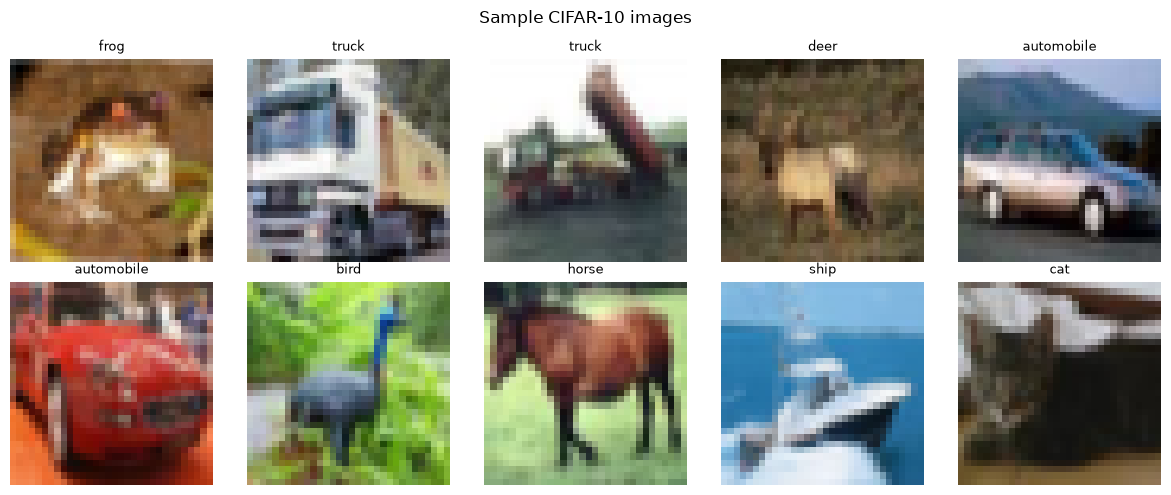

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_raw[i])
    ax.set_title(CLASS_NAMES[int(y_train[i])], fontsize=9)
    ax.axis("off")
fig.suptitle("Sample CIFAR-10 images")
plt.tight_layout()
plt.savefig("exp4_plot_01_sample_images.png", dpi=110, bbox_inches="tight")
plt.show()

## Model Definition

In [4]:
def build_transfer_model(base, dense_units=128, optimizer_name="adam", learning_rate=0.001):
    inputs = Input(shape=(32, 32, 3), name="cifar_input")
    features = base(inputs, training=False)
    features = GlobalAveragePooling2D(name="global_average_pooling")(features)
    features = Dense(dense_units, activation="relu", name="transfer_dense")(features)
    outputs = Dense(NUM_CLASSES, activation="softmax", name="cifar_output")(features)
    model = Model(inputs, outputs, name="mobilenetv2_cifar10")
    if optimizer_name == "sgd":
        opt = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        opt = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])
    return model

def metric_summary(model, x_test, y_test, y_test_one_hot):
    probs = model.predict(x_test, batch_size=128, verbose=0)
    preds = np.argmax(probs, axis=1)
    return {
        "accuracy": float(accuracy_score(y_test, preds)),
        "precision": float(precision_score(y_test, preds, average="macro", zero_division=0)),
        "recall": float(recall_score(y_test, preds, average="macro", zero_division=0)),
        "f1": float(f1_score(y_test, preds, average="macro", zero_division=0)),
        "loss": float(model.evaluate(x_test, y_test_one_hot, verbose=0)[0]),
        "predictions": preds,
        "confusion_matrix": confusion_matrix(y_test, preds).tolist(),
        "classification_report": classification_report(y_test, preds, target_names=CLASS_NAMES, digits=4, zero_division=0)
    }

## Frozen Base Training

In [5]:
base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(32, 32, 3))
base.trainable = False
frozen_model = build_transfer_model(base)
frozen_model.summary()
start = time.perf_counter()
frozen_history = frozen_model.fit(x_fit, y_fit, validation_data=(x_val, y_val), epochs=HEAD_EPOCHS, batch_size=BATCH_SIZE, verbose=2)
frozen_time = time.perf_counter() - start
frozen_metrics = metric_summary(frozen_model, x_test, y_test, y_test_one_hot)
frozen_metrics["training_time_seconds"] = frozen_time
frozen_metrics["parameters"] = int(frozen_model.count_params())
print(f"frozen accuracy: {frozen_metrics['accuracy']:.4f}")

/var/folders/9n/1s_b39b50yv1pdkgy1fvll800000gn/T/ipykernel_39016/182899827.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(32, 32, 3))


Model: "mobilenetv2_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar_input (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1, 1, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dense (Dense)          │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cifar_output (Dense)            │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (17 outputs left out)

1407/1407 - 16s - 11ms/step - accuracy: 0.3462 - loss: 1.7811 - val_accuracy: 0.3132 - val_loss: 1.8973


Epoch 10/10


1407/1407 - 17s - 12ms/step - accuracy: 0.3501 - loss: 1.7698 - val_accuracy: 0.3134 - val_loss: 1.9011


frozen accuracy: 0.3101


## Fine-Tuning

In [6]:
for layer in base.layers:
    layer.trainable = False
for layer in base.layers[-20:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True
fine_model = build_transfer_model(base)
fine_model.set_weights(frozen_model.get_weights())
fine_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
fine_model.summary()
start = time.perf_counter()
fine_history = fine_model.fit(x_fit, y_fit, validation_data=(x_val, y_val), epochs=FINE_TUNE_EPOCHS, batch_size=BATCH_SIZE, verbose=2)
fine_time = time.perf_counter() - start
fine_metrics = metric_summary(fine_model, x_test, y_test, y_test_one_hot)
fine_metrics["training_time_seconds"] = fine_time
fine_metrics["parameters"] = int(fine_model.count_params())
print(f"fine-tuned accuracy: {fine_metrics['accuracy']:.4f}")

Model: "mobilenetv2_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cifar_input (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1, 1, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transfer_dense (Dense)          │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cifar_output (Dense)            │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 1,360,138 (5.19 MB)

 Non-trainable params: 1,063,104 (4.06 MB)

Epoch 1/5


... (6 outputs left out)

1407/1407 - 21s - 15ms/step - accuracy: 0.5235 - loss: 1.3164 - val_accuracy: 0.5044 - val_loss: 1.4289


Epoch 5/5


1407/1407 - 21s - 15ms/step - accuracy: 0.5446 - loss: 1.2621 - val_accuracy: 0.5030 - val_loss: 1.4751


fine-tuned accuracy: 0.4964


## Training Curves

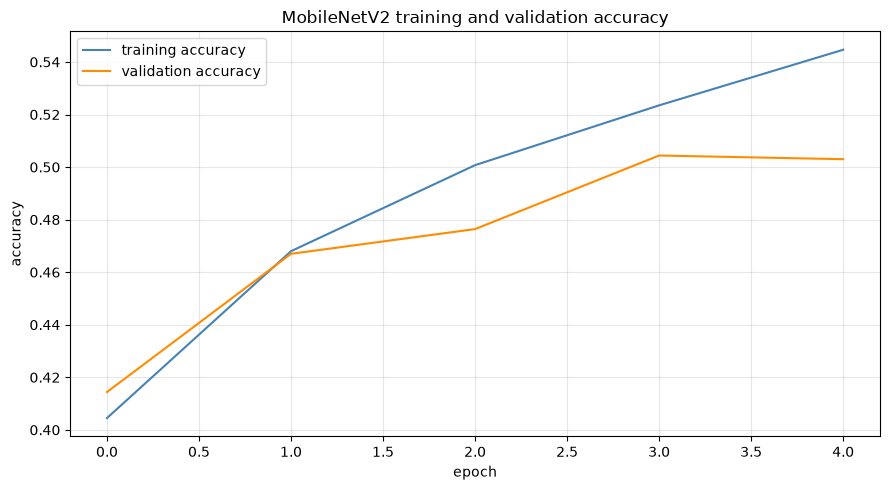

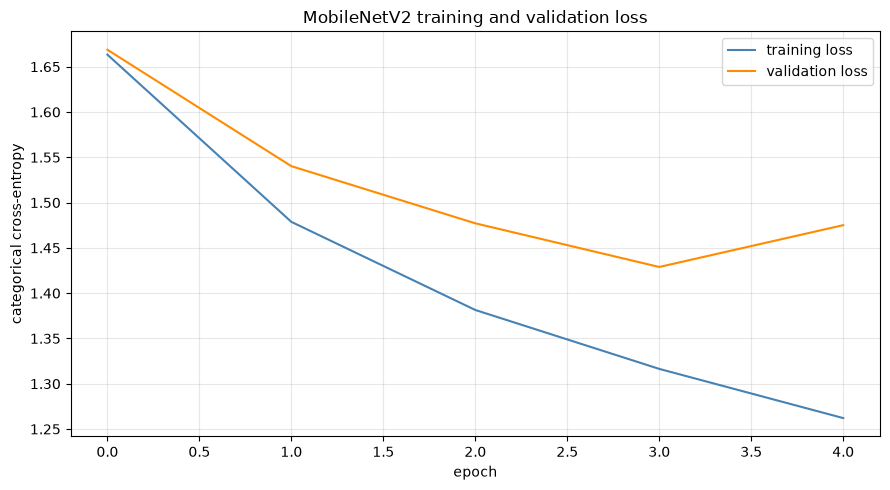

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(fine_history.history["accuracy"], label="training accuracy", color="steelblue")
ax.plot(fine_history.history["val_accuracy"], label="validation accuracy", color="darkorange")
ax.set_title("MobileNetV2 training and validation accuracy")
ax.set_xlabel("epoch")
ax.set_ylabel("accuracy")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exp4_plot_02_training_accuracy.png", dpi=110, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(fine_history.history["loss"], label="training loss", color="steelblue")
ax.plot(fine_history.history["val_loss"], label="validation loss", color="darkorange")
ax.set_title("MobileNetV2 training and validation loss")
ax.set_xlabel("epoch")
ax.set_ylabel("categorical cross-entropy")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exp4_plot_03_training_loss.png", dpi=110, bbox_inches="tight")
plt.show()

## Confusion Matrix

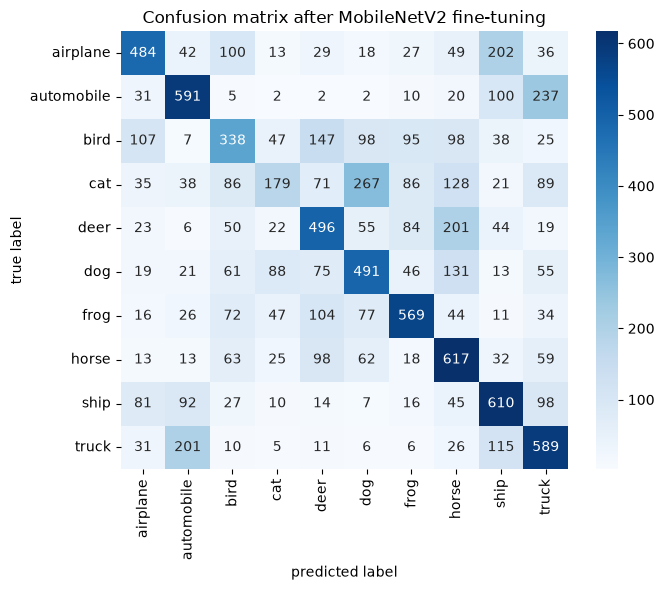

In [8]:
cm = np.asarray(fine_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title("Confusion matrix after MobileNetV2 fine-tuning")
ax.set_xlabel("predicted label")
ax.set_ylabel("true label")
plt.tight_layout()
plt.savefig("exp4_plot_04_confusion_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

## Misclassified Examples

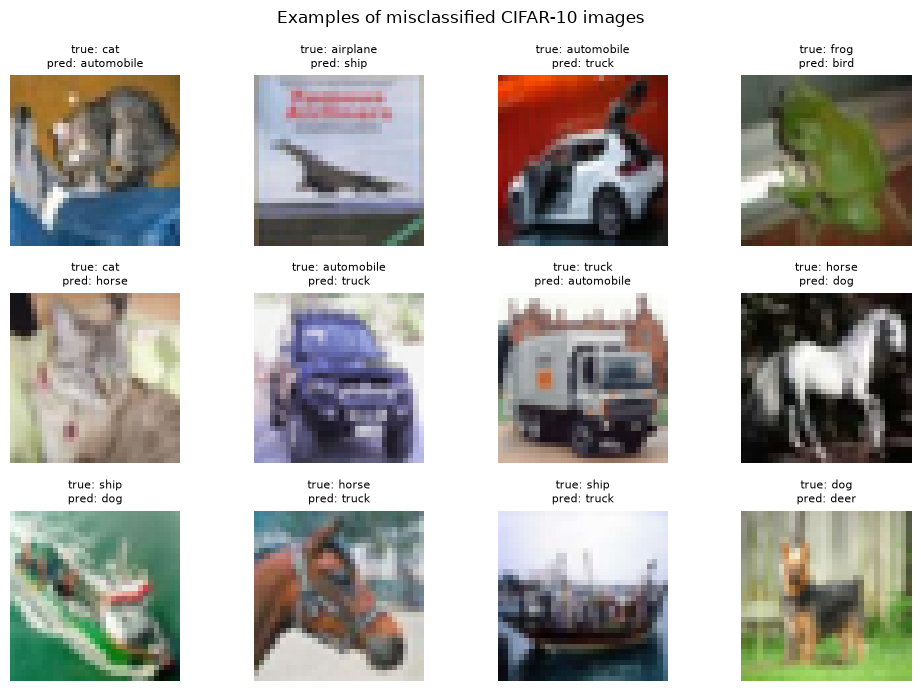

In [9]:
wrong = np.flatnonzero(fine_metrics["predictions"] != y_test)[:12]
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(x_test_raw[idx])
    ax.set_title(f"true: {CLASS_NAMES[y_test[idx]]}\npred: {CLASS_NAMES[fine_metrics['predictions'][idx]]}", fontsize=8)
    ax.axis("off")
fig.suptitle("Examples of misclassified CIFAR-10 images")
plt.tight_layout()
plt.savefig("exp4_plot_05_misclassified_images.png", dpi=110, bbox_inches="tight")
plt.show()

## Frozen vs Fine-Tuned Comparison

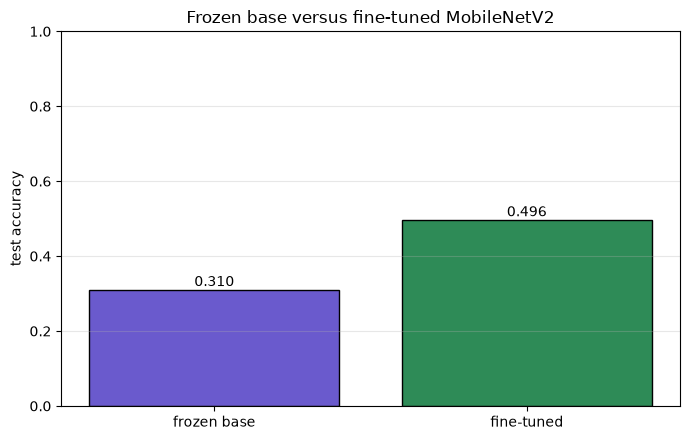

In [10]:
names = ["frozen base", "fine-tuned"]
vals = [frozen_metrics["accuracy"], fine_metrics["accuracy"]]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(names, vals, color=["slateblue","seagreen"], edgecolor="black")
ax.set_ylim(0, 1)
ax.set_ylabel("test accuracy")
ax.set_title("Frozen base versus fine-tuned MobileNetV2")
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f"{v:.3f}", ha="center")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("exp4_plot_06_frozen_finetuned.png", dpi=110, bbox_inches="tight")
plt.show()

## Hyperparameter Study

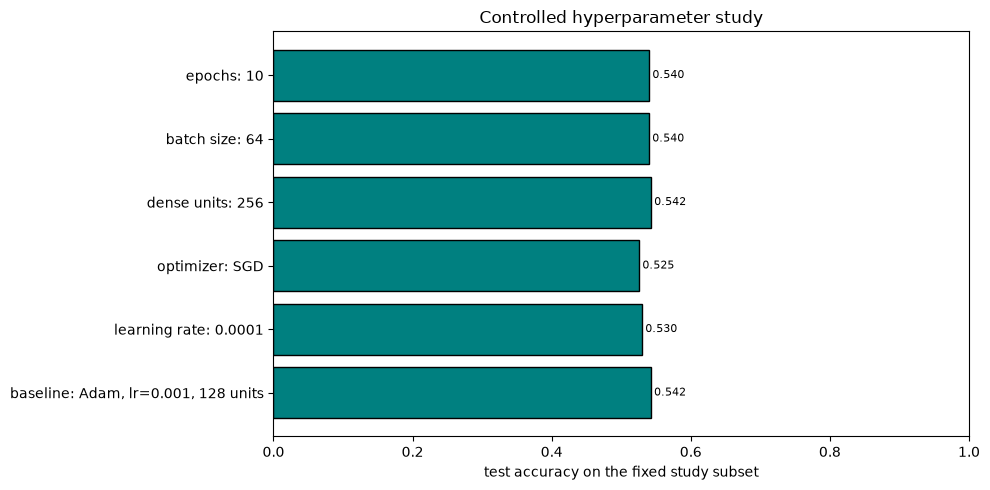

In [11]:
feature_model = Model(base.inputs[0], GlobalAveragePooling2D()(base.output))
features = feature_model.predict(x_train, batch_size=128, verbose=0)
study_labels = y_train_one_hot
rows = []
settings = [
    ("baseline: Adam, lr=0.001, 128 units", 128, "adam", 0.001, 32, 5),
    ("learning rate: 0.0001", 128, "adam", 0.0001, 32, 5),
    ("optimizer: SGD", 128, "sgd", 0.001, 32, 5),
    ("dense units: 256", 256, "adam", 0.001, 32, 5),
    ("batch size: 64", 128, "adam", 0.001, 64, 5),
    ("epochs: 10", 128, "adam", 0.001, 32, 10),
]
for label, units, opt_name, lr, bs, ep in settings:
    head = tf.keras.Sequential([Input(shape=(features.shape[1],)), Dense(units, activation="relu"), Dense(NUM_CLASSES, activation="softmax")])
    opt = tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9) if opt_name=="sgd" else tf.keras.optimizers.Adam(learning_rate=lr)
    head.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])
    h = head.fit(features, study_labels, validation_split=0.1, epochs=ep, batch_size=bs, verbose=0)
    rows.append({"label": label, "accuracy": float(h.history["val_accuracy"][-1])})

labels = [r["label"] for r in rows]
vals = [r["accuracy"] for r in rows]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, vals, color="teal", edgecolor="black")
ax.set_xlim(0, 1)
ax.set_xlabel("test accuracy on the fixed study subset")
ax.set_title("Controlled hyperparameter study")
for bar, v in zip(bars, vals):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig("exp4_plot_07_hyperparameter_study.png", dpi=110, bbox_inches="tight")
plt.show()
hyper_rows = rows

## Results Summary

In [12]:
results = {
    "seed": SEED,
    "head_epochs": HEAD_EPOCHS,
    "fine_tune_epochs": FINE_TUNE_EPOCHS,
    "frozen": {k: v for k, v in frozen_metrics.items() if k != "predictions"},
    "fine_tuned": {k: v for k, v in fine_metrics.items() if k != "predictions"},
    "hyperparameter_study": hyper_rows,
}
open("experiment_4_results.json","w").write(json.dumps(results, indent=2))
print(json.dumps({"frozen": round(frozen_metrics["accuracy"],4), "fine_tuned": round(fine_metrics["accuracy"],4)}, indent=2))

{
  "frozen": 0.3101,
  "fine_tuned": 0.4964
}
